# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Norelle CHY–GLASSCOCK   Student ID: B00825108
2. Full name: Thien Anh Nguyen  Student ID: B00817290
3. Full name: Isabelle Liew Yu Chen  Student ID: B00819132
4. Full name: Lio SUCHET--WANG  Student ID: B00818171

**Project role (consultant / data scientist / risk analyst):** Risk analyst (Climate Risk Analyst)

**Key quantity (one sentence, with unit):** Net EU ETS carbon cost of the aviation sector (EEA scope) = (verified emissions - free allowances) x annual mean EUA auction price, in million EUR per year, 2013-2025.

**Repo URL:** https://github.com/Lio0704/aidams-lab5-ChyGlasscock-LiewYuChen-Nguyen-SuchetWang.git

## Setup (given)

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = False  # set to False once your project data load below


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [11]:
DATA = Path(".")

def load_eea_aviation(path, region="All Countries"):
    """EEA EU ETS data-viewer export (UTF-16, tab-separated): one column per country x year."""
    raw = pd.read_csv(path, sep="\t", header=None, encoding="utf-16", dtype=str)
    countries = raw.iloc[0, 1:].str.strip()
    years = pd.to_numeric(raw.iloc[1, 1:].str.strip())
    rows = {}
    for i in range(3, len(raw)):
        label = str(raw.iloc[i, 0]).strip()
        if label in ("", "nan"):
            continue
        vals = raw.iloc[i, 1:].fillna("").str.replace(" ", "", regex=False)
        rows[label] = pd.to_numeric(vals.replace("", np.nan))
    df = pd.DataFrame(rows)
    df["country"], df["year"] = countries.values, years.values
    df = df[df.country == region].set_index("year")
    return pd.DataFrame({
        "emissions_mt": df["2. Verified emissions"],            # MtCO2, verified
        "free_mt": df["1.1 Freely allocated allowances"],       # million allowances
    })

if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    ets = load_eea_aviation(DATA / "eea_ets_aviation.csv")
    # EUA price: volume-weighted mean of all EEX primary auctions in the year (EUR/t)
    price = pd.read_csv(DATA / "eua_price_annual.csv", index_col="year")["eua_price_vwap"]
    panel = ets.join(price.rename("eua_eur"), how="inner")
    panel = panel.loc[2013:]          # 2012 = full-scope "stop the clock" year, not comparable
    panel["payable_mt"] = panel.emissions_mt - panel.free_mt
    panel["payable_share"] = panel.payable_mt / panel.emissions_mt
    # Mt x EUR/t = million EUR. Negative in 2020: COVID left a surplus of free allowances.
    panel["net_cost_meur"] = panel.payable_mt * panel.eua_eur
    series = (panel.reset_index()[["year", "net_cost_meur"]]
                   .rename(columns={"net_cost_meur": "value"})
                   .astype({"year": int, "value": float}))
    NAME = "Net EU ETS carbon cost of aviation (EEA scope)"
    UNIT = "million EUR / year"
    display(panel)
series.tail()

,emissions_mt,free_mt,eua_eur,payable_mt,payable_share,net_cost_meur
year,,,,,,
2013,53.49,32.13,4.38,21.35,0.40,93.53
2014,54.83,32.07,5.90,22.76,0.42,134.30
2015,57.11,31.71,7.62,25.39,0.44,193.50
2016,61.47,31.59,5.26,29.89,0.49,157.21
2017,64.42,32.66,5.78,31.76,0.49,183.56
2018,67.50,30.59,15.32,36.91,0.55,565.40
2019,68.18,30.14,24.64,38.04,0.56,937.28
2020,25.26,30.61,24.52,-5.35,-0.21,-131.08
2021,27.95,23.95,52.92,4.00,0.14,211.89


,year,value
8,2021,211.89
9,2022,"2,086.90"
10,2023,"2,639.19"
11,2024,"2,893.87"
12,2025,"3,774.60"


### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

Our key quantity is the net carbon cost the aviation sector pays under the EU ETS each year, computed as (verified emissions − free allowances) × annual mean EUA auction price, in million EUR; it rose from €94 m in 2013 to €3.8 bn in 2025 as the payable share grew from 40% to 82% and the carbon price rose from €4 to €73/t. This number drives our value proposal: it tells EU airlines how much carbon cost to budget and hedge once free allocation reaches zero in 2026, and at which combined oil/carbon price their EBIT margin would turn negative. Its main uncertainties are future emissions, which depend on traffic growth and fuel-efficiency assumptions (E), year-to-year swings in the EUA price (A), and the policy path, i.e. the carbon price level, SAF allowances and a possible extension of the ETS to extra-EEA flights (S). The historical series also contains breaks that weaken any trend fit: the COVID surplus that made 2020 negative (€−131 m), the UK leaving the system in 2021, and gap-filled 2025 data (E).

---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [12]:
def fit_predict(train, horizon, model="linear", level=0.90):
    tr = train.copy()
    if model == "loglinear":
        if (tr.value <= 0).any():
            # log undefined for the 2020 COVID surplus: fit on the positive years only
            print(f"loglinear: dropping non-positive years {tr.loc[tr.value <= 0, 'year'].tolist()}")
            tr = tr[tr.value > 0]
        y = np.log(tr.value.values)
    else:
        y = tr.value.values
    yr = tr.year.values.astype(float)
    tbar = yr.mean()
    X = np.column_stack([np.ones_like(yr), yr - tbar])
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    n, p = X.shape
    s = np.sqrt(resid @ resid / (n - p))
    tq = stats.t.ppf(0.5 + level / 2, df=n - p)

    fut = np.arange(train.year.max() + 1, train.year.max() + 1 + horizon)
    X0 = np.column_stack([np.ones(horizon), fut - tbar])
    mu = X0 @ beta
    lev = np.einsum("ij,jk,ik->i", X0, XtX_inv, X0)
    half = tq * s * np.sqrt(1 + lev)
    lo, hi = mu - half, mu + half
    if model == "loglinear":
        mu, lo, hi = np.exp(mu), np.exp(lo), np.exp(hi)   # exp(mean log) = median
    return pd.DataFrame({"year": fut, "mean": mu, "lo": lo, "hi": hi})

H = 5
train, test = series.iloc[:-H], series.iloc[-H:]
parts = []
for m in ["linear", "loglinear"]:
    p = fit_predict(train, H, m).assign(model=m)
    parts.append(p.merge(test.rename(columns={"value": "actual"}), on="year"))
backtest = pd.concat(parts, ignore_index=True)
backtest["inside"] = (backtest.actual >= backtest.lo) & (backtest.actual <= backtest.hi)
backtest

loglinear: dropping non-positive years [2020]


,year,mean,lo,hi,model,actual,inside
0,2021,458.75,-378.11,"1,295.60",linear,211.89,True
1,2022,501.42,-395.28,"1,398.13",linear,"2,086.90",False
2,2023,544.10,-419.53,"1,507.72",linear,"2,639.19",False
3,2024,586.77,-449.49,"1,623.03",linear,"2,893.87",False
4,2025,629.44,-484.04,"1,742.92",linear,"3,774.60",False
5,2021,"1,325.08",444.82,"3,947.30",loglinear,211.89,False
6,2022,"1,876.10",569.47,"6,180.74",loglinear,"2,086.90",True
7,2023,"2,656.25",723.02,"9,758.56",loglinear,"2,639.19",True
8,2024,"3,760.82",912.14,"15,506.16",loglinear,"2,893.87",True
9,2025,"5,324.72","1,145.04","24,761.21",loglinear,"3,774.60",True


### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

Years inside the 90% band (out of 5):
model
linear       1
loglinear    4

P(X >= k), X ~ Bin(5, 0.1)  [misses of a correctly calibrated 90% band]
  k = 0: 1.0000
  k = 1: 0.4095
  k = 2: 0.0815
  k = 3: 0.0086
  k = 4: 0.0005
  k = 5: 0.0000


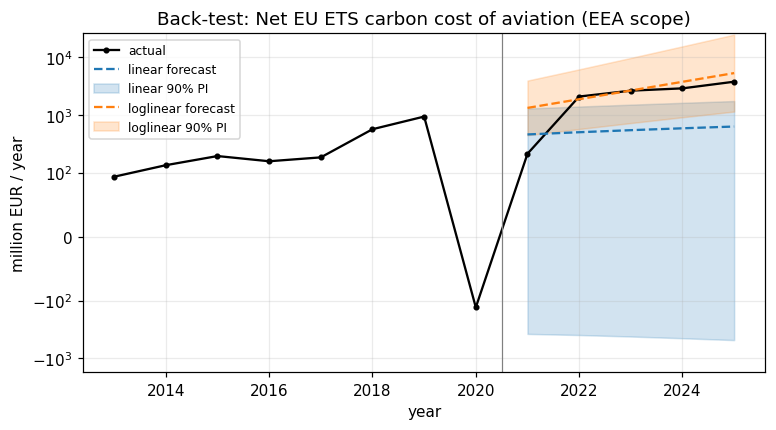

In [13]:
cov = backtest.groupby("model").inside.sum()
print("Years inside the 90% band (out of 5):"); print(cov.to_string())

print("\nP(X >= k), X ~ Bin(5, 0.1)  [misses of a correctly calibrated 90% band]")
for k in range(0, 6):
    print(f"  k = {k}: {stats.binom.sf(k - 1, 5, 0.1):.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(series.year, series.value, "k-o", ms=3, label="actual")
for m, c in [("linear", "tab:blue"), ("loglinear", "tab:orange")]:
    b = backtest[backtest.model == m]
    ax.plot(b.year, b["mean"], "--", color=c, label=f"{m} forecast")
    ax.fill_between(b.year, b.lo, b.hi, color=c, alpha=0.2, label=f"{m} 90% PI")
ax.axvline(train.year.max() + 0.5, color="grey", lw=0.8)
ax.set_yscale("symlog", linthresh=100)
ax.set_xlabel("year"); ax.set_ylabel(UNIT); ax.set_title(f"Back-test: {NAME}")
ax.legend(fontsize=8); plt.show()

**Your answer (Q2):**

(a) Over the 2021–2025 hold-out, the linear model has only 1 of 5 years inside its 90% band, while the log-linear model has 4 of 5; its one miss is 2021, when the cost was still depressed by COVID. (b) If a 90% band is well calibrated, the number of misses follows X ~ Bin(5, 0.1), so P(X ≥ 2) = 0.08 and P(X ≥ 3) = 0.009. Two or more misses should therefore make us doubt the band, and the linear model’s 4 misses (P = 0.0005) reject it clearly. (c) We keep the log-linear model, but only as a benchmark: its 2025 band runs from €1.1 bn to €24.8 bn, far too wide to be useful, and it can only be fitted after dropping the negative 2020 value. The gap between the two models shows that the cost grows multiplicatively, because the carbon price and the payable share rose together. That growth was driven by policy, not by a trend, so we project with the input-based simulation in Parts C–D instead.

## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [14]:
rows = []
for cut in range(series.year.min() + 9, series.year.max()):
    tr = series[series.year <= cut]
    for m in ["linear", "loglinear"]:
        p = fit_predict(tr, 3, m).merge(series.rename(columns={"value": "actual"}), on="year")
        p["h"] = p.year - cut
        p["inside"] = (p.actual >= p.lo) & (p.actual <= p.hi)
        rows.append(p.assign(model=m, cutoff=cut))
roll = pd.concat(rows)
roll.pivot_table(index="h", columns="model", values="inside", aggfunc=["mean", "count"])

loglinear: dropping non-positive years [2020]
loglinear: dropping non-positive years [2020]
loglinear: dropping non-positive years [2020]


mean            count          
model linear loglinear linear loglinear
h                                      
1       0.67      1.00      3         3
2       0.00      1.00      2         2
3       0.00      1.00      1         1

---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [15]:
N = 5_000
TARGET_YEAR = 2030
BASE_YEAR = int(series.year.max())               # 2025
E_BASE = panel.loc[BASE_YEAR, "emissions_mt"]     # verified aviation emissions, MtCO2
P_BASE = panel.loc[BASE_YEAR, "eua_eur"]          # EUA auction price, EUR/t
PAYABLE = 1.0   # free allocation for aviation ends in 2026 (SAF allowances ignored)

def compute_quantity(emis_mt, price_eur, payable=PAYABLE):
    """Net carbon cost (million EUR) = emissions (Mt) x payable share x EUA price (EUR/t)."""
    return emis_mt * payable * price_eur

# Input 1 - emissions growth g per year, 2025->2030 (epistemic: traffic growth net of fuel efficiency).
#   Triangular(-1%, +2%, +4.5%): +4.5% ~ pre-COVID 2014-2019 trend, -1% = demand hit from
#   high fares / oil shock, mode +2% ~ IATA-style traffic growth minus ~1.5%/yr efficiency gains.
def draw_emissions(rng, n, h, g=None):
    if g is None:
        g = rng.triangular(-0.01, 0.02, 0.045, n)
    return E_BASE * (1 + g) ** h, g

# Input 2 - EUA price in the target year (aleatoric market risk + scenario level).
#   Lognormal around a scenario median; sigma = 0.35 over 5 years, matching the
#   2021-2025 swings (EUR 53 -> 83 -> 65 -> 73).
SIGMA_5Y = 0.35
def draw_price(rng, n, h, median_target):
    med = P_BASE * (median_target / P_BASE) ** (h / 5)        # geometric path to the target
    return med * np.exp(rng.normal(0, SIGMA_5Y * np.sqrt(h / 5), n))

def summarise(x):
    q05, q25, q50, q75, q95 = np.percentile(x, [5, 25, 50, 75, 95])
    return dict(median=q50, lo90=q05, hi90=q95, lo50=q25, hi50=q75,
                rel_halfwidth=(q95 - q05) / 2 / q50)

h = TARGET_YEAR - BASE_YEAR
BASE_PRICE_2030 = 90.0     # central scenario (project matrix mid point)
rng_c = np.random.default_rng(SEED)
emis, g_draw = draw_emissions(rng_c, N, h)
prc = draw_price(rng_c, N, h, BASE_PRICE_2030)
cost = compute_quantity(emis, prc)

full = summarise(cost)
fix_emis = summarise(compute_quantity(np.median(emis), prc))
fix_price = summarise(compute_quantity(emis, np.median(prc)))
sens = pd.DataFrame({"all inputs uncertain": full,
                     "emissions fixed at median": fix_emis,
                     "carbon price fixed at median": fix_price}).T
print(f"{TARGET_YEAR} net carbon cost, central scenario (EUR {BASE_PRICE_2030:.0f}/t median):")
sens

2030 net carbon cost, central scenario (EUR 90/t median):


,median,lo90,hi90,lo50,hi50,rel_halfwidth
all inputs uncertain,"6,141.48","3,414.43","11,121.20","4,851.70","7,816.27",0.63
emissions fixed at median,"6,119.79","3,438.58","11,022.50","4,886.80","7,792.47",0.62
carbon price fixed at median,"6,119.79","5,560.90","6,683.98","5,871.26","6,361.41",0.09


### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

(a) In the central scenario (EUA median €90/t in 2030), the 2030 net carbon cost has a median of €6.1 bn and a 90% interval of €3.4–11.1 bn, a relative half-width of 63%. (b) Fixing the carbon price at its median shrinks the half-width from 63% to 9%, whereas fixing emissions barely changes it (62%). The carbon price is therefore the dominant input; it is mainly aleatoric (market volatility), with a scenario component in its long-run level. (c) With one more week, we would collect Eurocontrol traffic forecasts, airline fleet-renewal plans and the volume of SAF allowances to narrow the emissions path. That would only reduce the small emissions-driven part of the range; the price-driven part would remain whatever data we collect, so we treat it through scenarios and hedging rather than trying to forecast it away.

---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

In [16]:
SCENARIOS = {
    # name: (EUA price median in 2030, growth range override or None)
    "Low carbon price (EUR 70/t)":  70.0,
    "Central (EUR 90/t)":           90.0,
    "High carbon price (EUR 150/t)": 150.0,
}

def simulate_path(median_2030, seed=SEED, years=range(BASE_YEAR + 1, TARGET_YEAR + 1)):
    r = np.random.default_rng(seed)
    g = r.triangular(-0.01, 0.02, 0.045, N)       # same growth draw along the path
    z = r.normal(0, 1, N)                          # one price shock, scaled by sqrt(h)
    out = {}
    for y in years:
        hh = y - BASE_YEAR
        e = E_BASE * (1 + g) ** hh
        med = P_BASE * (median_2030 / P_BASE) ** (hh / 5)
        p = med * np.exp(SIGMA_5Y * np.sqrt(hh / 5) * z)
        out[y] = compute_quantity(e, p)
    return out

paths = {name: simulate_path(m) for name, m in SCENARIOS.items()}
scen = pd.DataFrame({name: summarise(p[TARGET_YEAR]) for name, p in paths.items()}).T
scen["width90"] = scen.hi90 - scen.lo90
display(scen)

med = scen["median"]
gap = med.max() - med.min()
print(f"Largest gap between scenario medians: {gap:,.0f} {UNIT}")
print(f"90% width within central scenario:     {scen.loc['Central (EUR 90/t)', 'width90']:,.0f} {UNIT}")
print(f"Ratio gap / within-scenario width:     {gap / scen.loc['Central (EUR 90/t)', 'width90']:.2f}")

,median,lo90,hi90,lo50,hi50,rel_halfwidth,width90
Low carbon price (EUR 70/t),"4,776.71","2,655.67","8,649.82","3,773.55","6,079.32",0.63,"5,994.15"
Central (EUR 90/t),"6,141.48","3,414.43","11,121.20","4,851.70","7,816.27",0.63,"7,706.77"
High carbon price (EUR 150/t),"10,235.80","5,690.71","18,535.33","8,086.17","13,027.12",0.63,"12,844.62"


Largest gap between scenario medians: 5,459 million EUR / year
90% width within central scenario:     7,707 million EUR / year
Ratio gap / within-scenario width:     0.71


### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

The largest gap between scenario medians is €5.5 bn (€4.8 bn at €70/t versus €10.2 bn at €150/t). The 90% interval inside the central scenario alone is €7.7 bn wide, so the within-scenario uncertainty is larger than the gap between scenarios (ratio 0.71), and the scenario bands overlap heavily. A single fan chart would hide the fact that the policy choice shifts the whole distribution, while showing scenarios without bands would overstate how well each one is known. We therefore present one band per scenario on the same chart, and our key message is that carbon-price volatility alone can move the cost as much as the choice of policy scenario.

---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates…):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

In [17]:
# Part E skipped (optional): our key quantity uses no text-extracted variable.

---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

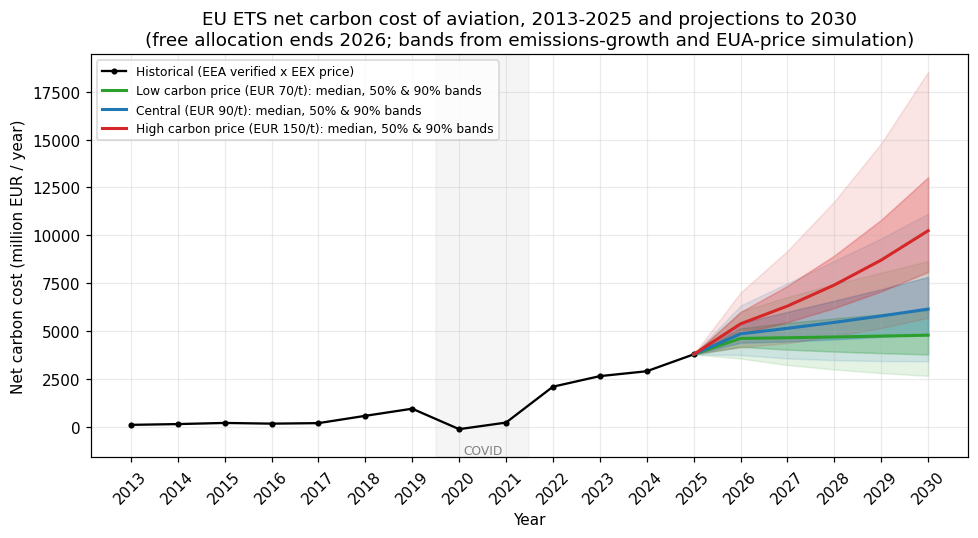

In [18]:
colors = {"Low carbon price (EUR 70/t)": "tab:green",
          "Central (EUR 90/t)": "tab:blue",
          "High carbon price (EUR 150/t)": "tab:red"}
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(series.year, series.value, "k-o", ms=3, lw=1.5, label="Historical (EEA verified x EEX price)")
for name, p in paths.items():
    yrs = [BASE_YEAR] + list(p)
    q = np.array([[series.value.iloc[-1]] * 5] +
                 [np.percentile(p[y], [5, 25, 50, 75, 95]) for y in p])
    c = colors[name]
    ax.fill_between(yrs, q[:, 0], q[:, 4], color=c, alpha=0.12)
    ax.fill_between(yrs, q[:, 1], q[:, 3], color=c, alpha=0.28)
    ax.plot(yrs, q[:, 2], color=c, lw=2, label=f"{name}: median, 50% & 90% bands")
ax.axvspan(2019.5, 2021.5, color="grey", alpha=0.08)
ax.text(2020.5, -900, "COVID", ha="center", va="top", fontsize=8, color="grey")
ax.set_xticks(range(2013, TARGET_YEAR + 1)); ax.tick_params(axis="x", labelrotation=45)
ax.set_ylim(-1600, None)
ax.set_xlabel("Year")
ax.set_ylabel("Net carbon cost (million EUR / year)")
ax.set_title("EU ETS net carbon cost of aviation, 2013-2025 and projections to 2030\n"
             "(free allocation ends 2026; bands from emissions-growth and EUA-price simulation)")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("fig_uncertainty.png", dpi=200)
plt.show()

## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.

### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is …"*

**Your answer (Q6):**

Under a central scenario in which the EUA price reaches €90/t and free allocation ends in 2026, the net EU ETS carbon cost of aviation in 2030 has a median of €6.1 bn (90% interval: €3.4–11.1 bn). A back-test on 2021–2025 shows that simple trends are unreliable: a linear trend captured only 1 of 5 held-out years and a log-linear trend 4 of 5, with an impractically wide band. The range is driven mainly by the carbon price; fixing it cuts the interval half-width from 63% to 9%. Moving from a €70/t to a €150/t scenario shifts the median by €5.5 bn. Within this model, it is very likely that the cost exceeds €3.4 bn in 2030. Our main limitations are that we ignore SAF allowances, a possible extension of the ETS to extra-EEA flights, and the pass-through of carbon costs to fares.

**Your answer (Q7):**

“Because the range is this wide, the decision that changes is how much of their 2026–2030 carbon cost EU airlines should lock in through forward EUA purchases, rather than budgeting for a single central carbon price.”